In [1]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.quantum_info.states.random import random_statevector
from qiskit.circuit.library import Initialize
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

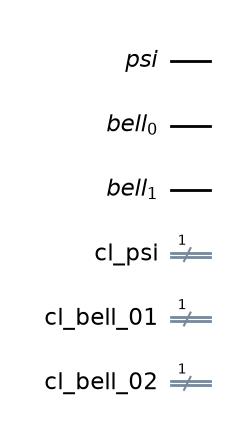

In [2]:
psi = QuantumRegister(1, "psi")
cl_psi = ClassicalRegister(1, "cl_psi")

bell = QuantumRegister(2, "bell")
cl_bell_01 = ClassicalRegister(1, "cl_bell_01")
cl_bell_02 = ClassicalRegister(1, "cl_bell_02")

qc = QuantumCircuit(psi, cl_psi, bell, cl_bell_01, cl_bell_02)
qc.draw("mpl")


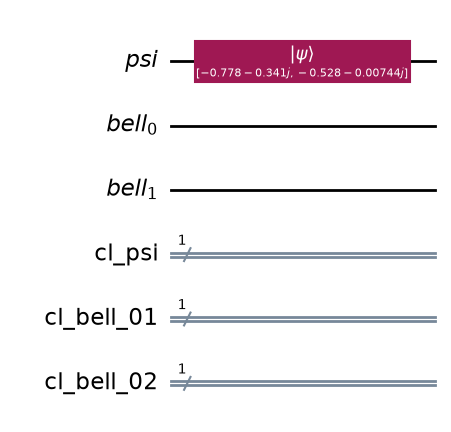

In [ ]:
random_vector = random_statevector(2)
# random_vector = np.array([1/np.sqrt(2), 1/np.sqrt(2)])
probs = np.abs(random_vector)**2
probs = {0: probs[0], 1: probs[1]}

state = Initialize(random_vector)
qc.append(state, psi)
qc.draw("mpl")

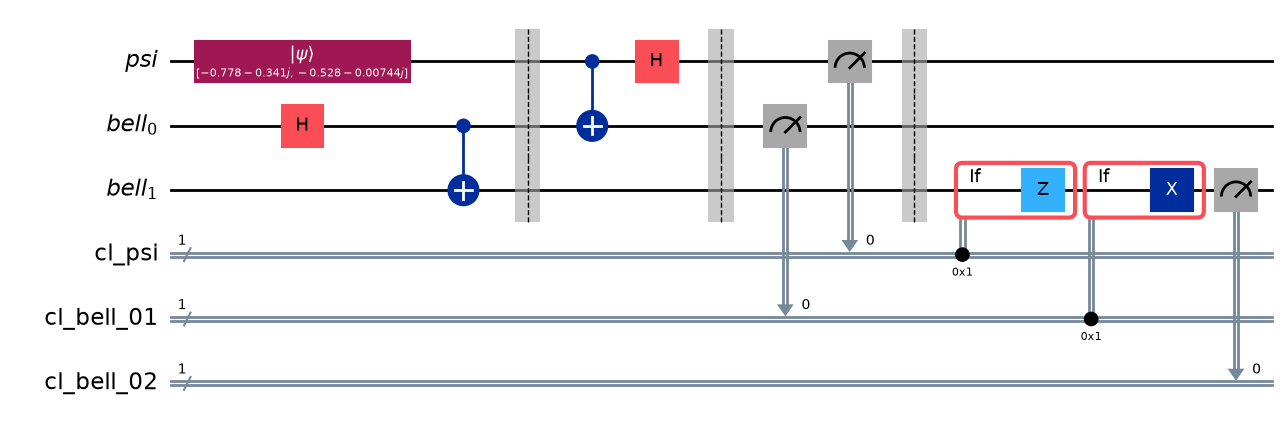

In [4]:
qc.h(bell[0])
qc.cx(bell[0], bell[1])
qc.barrier()
qc.cx(psi, bell[0])
qc.h(psi)
qc.barrier()
qt_sv = Statevector.from_circuit(qc)
qc.measure(bell[0], cl_bell_01)
qc.measure(psi, cl_psi)
qc.barrier()
with qc.if_test((cl_psi, True)):
    qc.z(bell[1])

with qc.if_test((cl_bell_01, True)):
    qc.x(bell[1])
qc.measure(bell[1], cl_bell_02)
qc.draw("mpl")

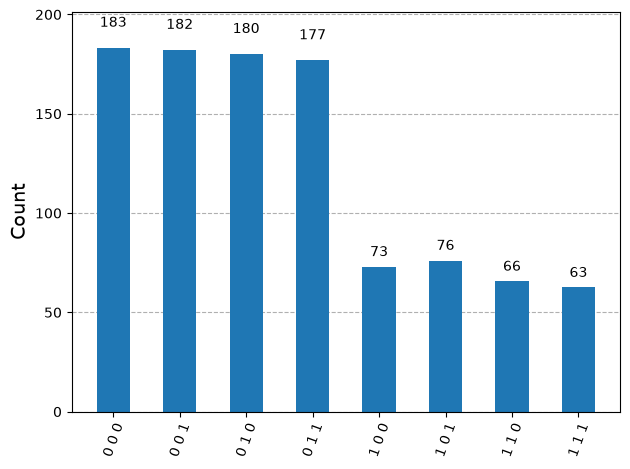

In [5]:
sim = AerSimulator()

result = sim.run(qc, shots = 1000).result()

plot_histogram(result.get_counts())

In [6]:
probs

{0: np.float64(0.7213831801453656), 1: np.float64(0.27861681985463466)}

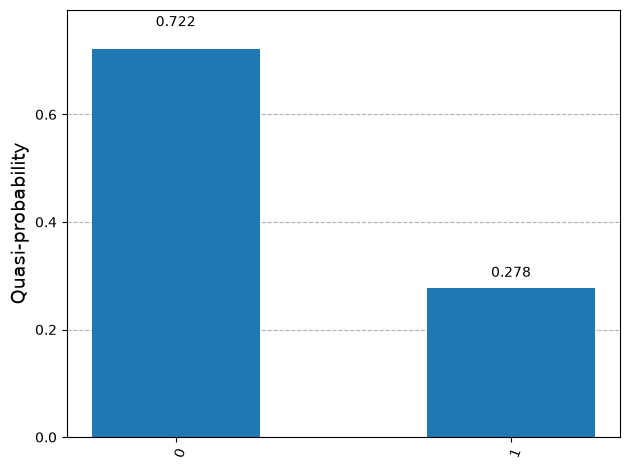

In [7]:
from collections import Counter

receiver_count = Counter()

for k, v in result.get_counts().items():
    receiver_count[k[0]] += v/1000


plot_histogram(receiver_count)


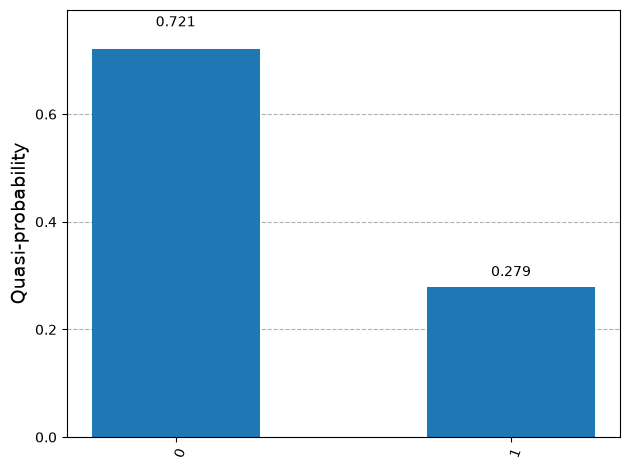

In [8]:
plot_histogram(probs)

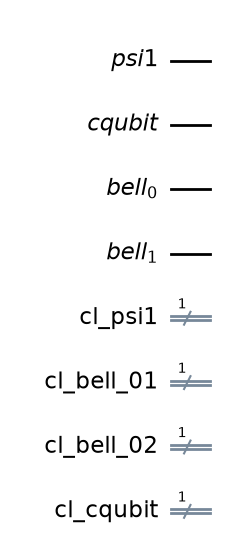

In [17]:
psi1 = QuantumRegister(1, "psi1")
cqubit = QuantumRegister(1, "cqubit")

cl_cqubit = ClassicalRegister(1, "cl_cqubit")
cl_psi1 = ClassicalRegister(1, "cl_psi1")

bell2 = QuantumRegister(2, "bell")
cl_bell_01 = ClassicalRegister(1, "cl_bell_01")
cl_bell_02 = ClassicalRegister(1, "cl_bell_02")

qc2 = QuantumCircuit(psi1, cqubit, cl_psi1, bell2, cl_bell_01, cl_bell_02, cl_cqubit)
qc2.draw("mpl")


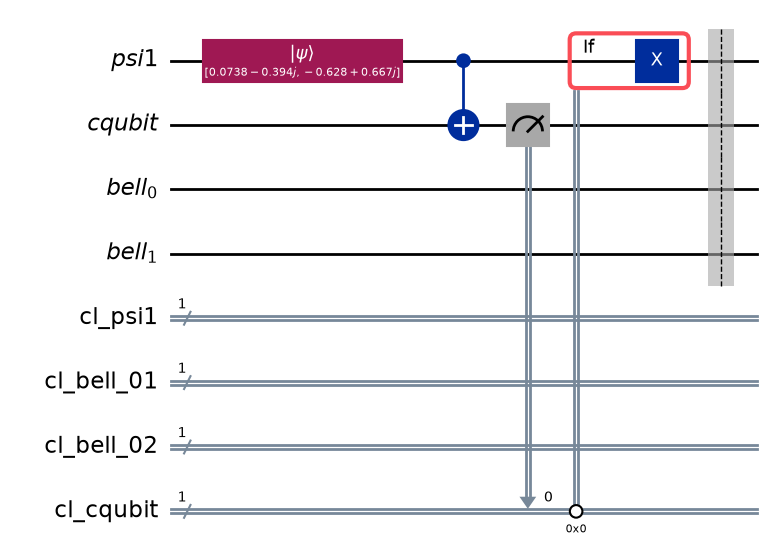

In [18]:
random_vector = random_statevector(2)
state = Initialize(random_vector)
qc2.append(state, psi1)

qc2.cx(psi1[0], cqubit[0])

qc2.measure(cqubit[0], cl_cqubit[0])

with qc2.if_test((cl_cqubit, 0)):
    qc2.x(psi1[0])

qc2.barrier()
qc2.draw('mpl')

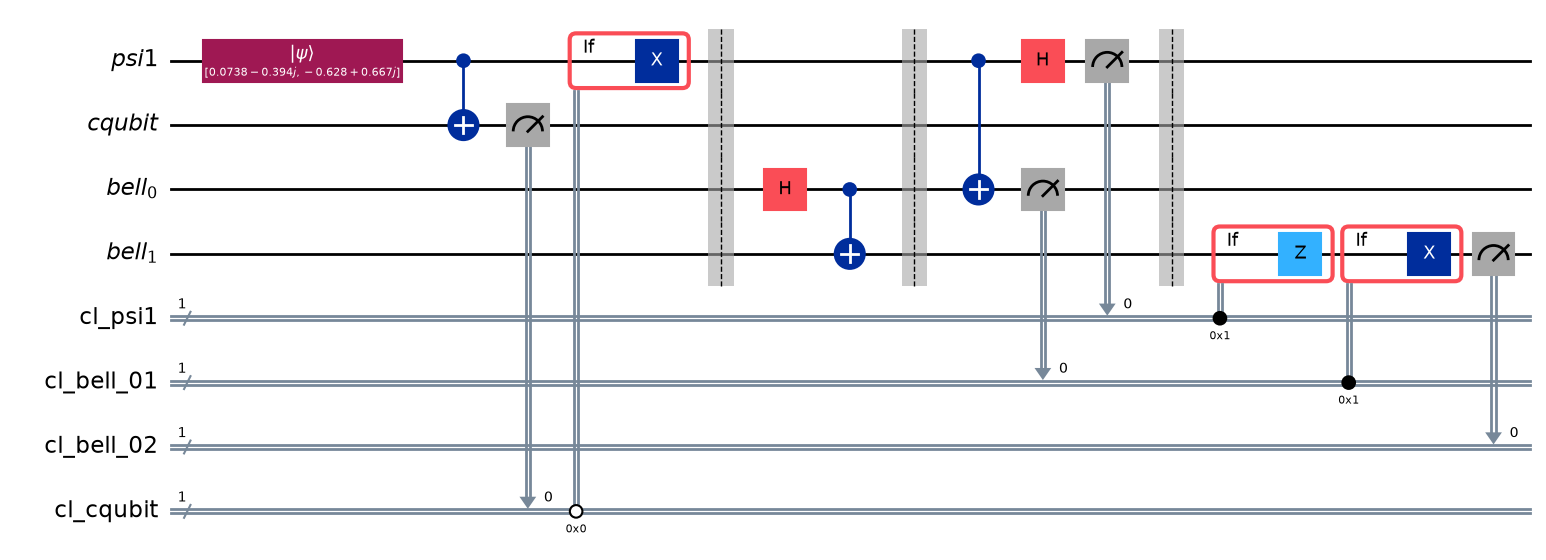

In [19]:
qc2.h(bell2[0])
qc2.cx(bell2[0], bell2[1])
qc2.barrier()

qc2.cx(psi1[0], bell2[0])
qc2.h(psi1[0])

qc2.measure(psi1[0], cl_psi1[0])
qc2.measure(bell2[0], cl_bell_01[0])
qc2.barrier()

with qc2.if_test((cl_psi1, 1)):
    qc2.z(bell2[1])

with qc2.if_test((cl_bell_01, 1)):
    qc2.x(bell2[1])

qc2.measure(bell2[1], cl_bell_02[0])
qc2.draw('mpl')

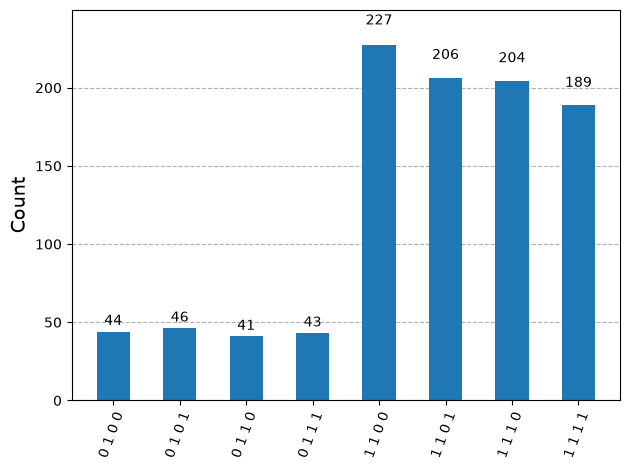

In [21]:
sim = AerSimulator()

result = sim.run(qc2, shots = 1000).result()

plot_histogram(result.get_counts())